# Crypto Risk Factors — v1 Baseline

30-day rolling volatility, skewness, kurtosis and Amihud illiquidity for BTC, ETH and BNB (3 years of daily data), with correlation analysis and OLS regressions of daily returns on the four factors.

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from datetime import datetime, timedelta
import os
import warnings
warnings.filterwarnings('ignore')

# Data download
tickers = ['BTC-USD', 'ETH-USD', 'BNB-USD']
end_date = datetime.today()
start_date = end_date - timedelta(days=3*365) 

data = {}
for ticker in tickers:  
    temp_data = yf.download(ticker, start=start_date, end=end_date, interval='1d')
    if not temp_data.empty:
        data[ticker] = temp_data

close_prices = pd.DataFrame()
volumes = pd.DataFrame()

for ticker, df in data.items():
    close_prices[ticker] = df['Close']
    volumes[ticker] = df['Volume']

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [2]:
def compute_required_risk_metrics(close_prices, volumes, window=30):

    # Daily returns
    daily_returns = np.log(close_prices / close_prices.shift(1)).dropna()
    
    # Required risk metrics
    risk_metrics = {}
    
    for ticker in close_prices.columns:
        returns = daily_returns[ticker]
        
        # Calculate required metrics
        rolling_vol = returns.rolling(window).std() * np.sqrt(365)  # Annualized volatility
        rolling_skew = returns.rolling(window).apply(skew)
        rolling_kurt = returns.rolling(window).apply(kurtosis)
        
        # Liquidity metrics
        vol_data = volumes[ticker].dropna()
        price_data = close_prices[ticker].dropna()
        common_idx = returns.index.intersection(vol_data.index)
        
        dollar_volume = (vol_data * price_data).reindex(common_idx)
        amihud_ratio = (np.abs(returns) / dollar_volume).rolling(window).mean()
        
        risk_metrics[ticker] = pd.DataFrame({
            'volatility': rolling_vol,
            'skewness': rolling_skew,
            'kurtosis': rolling_kurt,
            'amihud_ratio': amihud_ratio
        })
    
    return risk_metrics, daily_returns

def analyze_risk_correlations(risk_metrics):

    all_correlations = {}
    
    for ticker in risk_metrics.keys():
        risk_data = risk_metrics[ticker].dropna()
        
        if len(risk_data) > 10:
            corr_matrix = risk_data.corr()
            all_correlations[ticker] = corr_matrix
    
    # Cross-asset correlations for each risk type
    cross_asset_correlations = {}
    risk_types = ['volatility', 'skewness', 'kurtosis', 'amihud_ratio']
    
    for risk_type in risk_types:
        risk_data = pd.DataFrame()
        for ticker in risk_metrics.keys():
            if risk_type in risk_metrics[ticker].columns:
                risk_data[ticker] = risk_metrics[ticker][risk_type].dropna()
        
        if len(risk_data.columns) > 1 and len(risk_data) > 30:
            cross_corr = risk_data.corr()
            cross_asset_correlations[risk_type] = cross_corr
    
    return {
        'individual_correlations': all_correlations,
        'cross_asset_correlations': cross_asset_correlations
    }

def risk_factor_regression_analysis(daily_returns, risk_metrics):

    results = {}
    
    for ticker in daily_returns.columns:
        returns = daily_returns[ticker].dropna()
        risk_data = risk_metrics[ticker].dropna()
        
        common_idx = returns.index.intersection(risk_data.index)
        X = risk_data.loc[common_idx].dropna()
        y = returns.loc[X.index]
        
        if len(X) > 10:
            model = LinearRegression()
            model.fit(X, y)
            
            from scipy import stats
            params = np.append(model.intercept_, model.coef_)
            predictions = model.predict(X)
            
            X_with_const = np.append(np.ones((len(X), 1)), X, axis=1)
            
            MSE = (sum((y - predictions)**2)) / (X_with_const.shape[0] - X_with_const.shape[1])
            var_b = MSE * (np.linalg.inv(X_with_const.T.dot(X_with_const)).diagonal())
            sd_b = np.sqrt(var_b)
            
            # calculate p and t
            ts_b = params / sd_b
            p_values = [2 * (1 - stats.t.cdf(np.abs(i), (len(X_with_const) - len(X_with_const[0])))) for i in ts_b]
            
            results[ticker] = {
                'coefficients': pd.Series(model.coef_, index=X.columns),
                'r_squared': model.score(X, y),
                'intercept': model.intercept_,
                'p_values': pd.Series(p_values[1:], index=X.columns),  
                't_stats': pd.Series(ts_b[1:], index=X.columns)  
            }
    
    return results


def create_visualizations(risk_metrics, regression_results):

    # Correlation analysis
    correlation_analysis = analyze_risk_correlations(risk_metrics)
    
    # Create main visualization figure - MODIFIED TO SHOW ALL INDIVIDUAL CORRELATIONS
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    
    # 1. Individual cryptocurrency risk metric correlations for ALL tickers
    individual_correlations = correlation_analysis['individual_correlations']
    
    # Plot individual correlations for all tickers
    for i, (ticker, corr_matrix) in enumerate(individual_correlations.items()):
        row = i // 3
        col = i % 3
        sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', 
                   center=0, square=True, ax=axes[row, col])
        axes[row, col].set_title(f'{ticker} Risk Metrics Correlation')
    
    # Hide any unused subplots
    for i in range(len(individual_correlations), 6):
        row = i // 3
        col = i % 3
        axes[row, col].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    
    # Create separate figure for cross-asset correlations
    cross_correlations = correlation_analysis['cross_asset_correlations']
    num_cross = len(cross_correlations)
    if num_cross > 0:
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))
        
        # Plot all cross-asset correlations
        for i, (risk_type, corr_matrix) in enumerate(cross_correlations.items()):
            row = i // 2
            col = i % 2
            sns.heatmap(corr_matrix, annot=True, cmap='viridis', 
                       center=0, square=True, ax=axes[row, col])
            axes[row, col].set_title(f'Cross-Asset {risk_type.title()} Correlation')
        
        # Hide any unused subplots
        for i in range(num_cross, 4):
            row = i // 2
            col = i % 2
            axes[row, col].set_visible(False)
        
        plt.tight_layout()
        plt.show()
    
    # Create figure for regression coefficients
    coef_data = []
    for ticker, result in regression_results.items():
        for factor, coef in result['coefficients'].items():
            coef_data.append({'Ticker': ticker, 'Factor': factor, 'Coefficient': coef})
    
    coef_df = pd.DataFrame(coef_data)
    if not coef_df.empty:
        # 创建单个图形，而不是子图
        plt.figure(figsize=(12, 6))
        sns.barplot(data=coef_df, x='Factor', y='Coefficient', hue='Ticker')
        plt.title('Risk Factor Regression Coefficients')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
      
    # Risk metrics time series
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    for i, risk_type in enumerate(['volatility', 'skewness', 'kurtosis', 'amihud_ratio']):
        ax = axes[i//2, i%2]
        for ticker in risk_metrics.keys():
            if risk_type in risk_metrics[ticker].columns:
                data = risk_metrics[ticker][risk_type].dropna()
                ax.plot(data.index, data, label=ticker, linewidth=1.5)
        ax.set_title(f'{risk_type.title()} Over Time')
        ax.set_xlabel('Date')
        ax.set_ylabel(risk_type.title())
        ax.legend()
        ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

def save_plots(risk_metrics, regression_results, save_dir='risk_analysis_plots'):

    if not os.path.exists(save_dir):
        os.makedirs(save_dir)
    
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    
    # Save ALL individual correlation heatmaps
    correlation_analysis = analyze_risk_correlations(risk_metrics)
    individual_correlations = correlation_analysis['individual_correlations']
    
    for ticker, corr_matrix in individual_correlations.items():
        plt.figure(figsize=(8, 6))
        sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, square=True)
        plt.title(f'{ticker} Risk Metrics Correlation')
        plt.tight_layout()
        plt.savefig(f'{save_dir}/{ticker}_correlation_{timestamp}.png', dpi=300, bbox_inches='tight')
        plt.close()
    
    # Save ALL cross-asset correlation heatmaps
    cross_correlations = correlation_analysis['cross_asset_correlations']
    for risk_type, corr_matrix in cross_correlations.items():
        plt.figure(figsize=(8, 6))
        sns.heatmap(corr_matrix, annot=True, cmap='viridis', center=0, square=True)
        plt.title(f'Cross-Asset {risk_type.title()} Correlation')
        plt.tight_layout()
        plt.savefig(f'{save_dir}/cross_asset_{risk_type}_correlation_{timestamp}.png', dpi=300, bbox_inches='tight')
        plt.close()
    
    # Save regression coefficients
    coef_data = []
    for ticker, result in regression_results.items():
        for factor, coef in result['coefficients'].items():
            coef_data.append({'Ticker': ticker, 'Factor': factor, 'Coefficient': coef})
    
    coef_df = pd.DataFrame(coef_data)
    if not coef_df.empty:
        plt.figure(figsize=(10, 6))
        sns.barplot(data=coef_df, x='Factor', y='Coefficient', hue='Ticker')
        plt.title('Risk Factor Regression Coefficients')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.savefig(f'{save_dir}/regression_coefficients_{timestamp}.png', dpi=300, bbox_inches='tight')
        plt.close()
    
    # Save risk metrics time series
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    for i, risk_type in enumerate(['volatility', 'skewness', 'kurtosis', 'amihud_ratio']):
        ax = axes[i//2, i%2]
        for ticker in risk_metrics.keys():
            if risk_type in risk_metrics[ticker].columns:
                data = risk_metrics[ticker][risk_type].dropna()
                ax.plot(data.index, data, label=ticker, linewidth=1.5)
        ax.set_title(f'{risk_type.title()} Over Time')
        ax.set_xlabel('Date')
        ax.set_ylabel(risk_type.title())
        ax.legend()
        ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f'{save_dir}/risk_metrics_timeseries_{timestamp}.png', dpi=300, bbox_inches='tight')
    plt.close()

def display_regression_results(regression_results):
    
    for ticker, result in regression_results.items():
        print(f"\n{ticker}:")
        print(f"  R-squared: {result['r_squared']:.4f}")
        print(f"  Intercept: {result['intercept']:.6f}")
        print("\n  Coefficients:")
        
        # Create a DataFrame for better formatting
        coef_df = pd.DataFrame({
            'Coefficient': result['coefficients'],
            't-Statistic': result['t_stats'],
            'p-Value': result['p_values']
        })

        # Format the DataFrame for display
        display_df = coef_df.copy()
        display_df['Coefficient'] = display_df['Coefficient'].apply(lambda x: f"{x:.6f}")
        display_df['t-Statistic'] = display_df['t-Statistic'].apply(lambda x: f"{x:.4f}")
        display_df['p-Value'] = display_df['p-Value'].apply(lambda x: f"{x:.4f}")
        
        print(display_df.to_string())   


BTC-USD:
  R-squared: 0.0131
  Intercept: 0.000811

  Coefficients:
             Coefficient t-Statistic p-Value
volatility      0.001110      0.2056  0.8371
skewness        0.003617      3.6434  0.0003
kurtosis       -0.000371     -0.8522  0.3943
amihud_ratio   -0.000000     -0.0000  1.0000

ETH-USD:
  R-squared: 0.0121
  Intercept: 0.004409

  Coefficients:
             Coefficient t-Statistic p-Value
volatility     -0.005232     -1.0138  0.3109
skewness        0.004657      3.4428  0.0006
kurtosis       -0.000618     -1.2608  0.2077
amihud_ratio   -0.000000     -0.0000  1.0000

BNB-USD:
  R-squared: 0.0103
  Intercept: 0.002228

  Coefficients:
             Coefficient t-Statistic p-Value
volatility      0.000675      0.1291  0.8973
skewness        0.002508      2.1863  0.0290
kurtosis       -0.000825     -1.4536  0.1464
amihud_ratio   -0.000000     -0.0000  1.0000


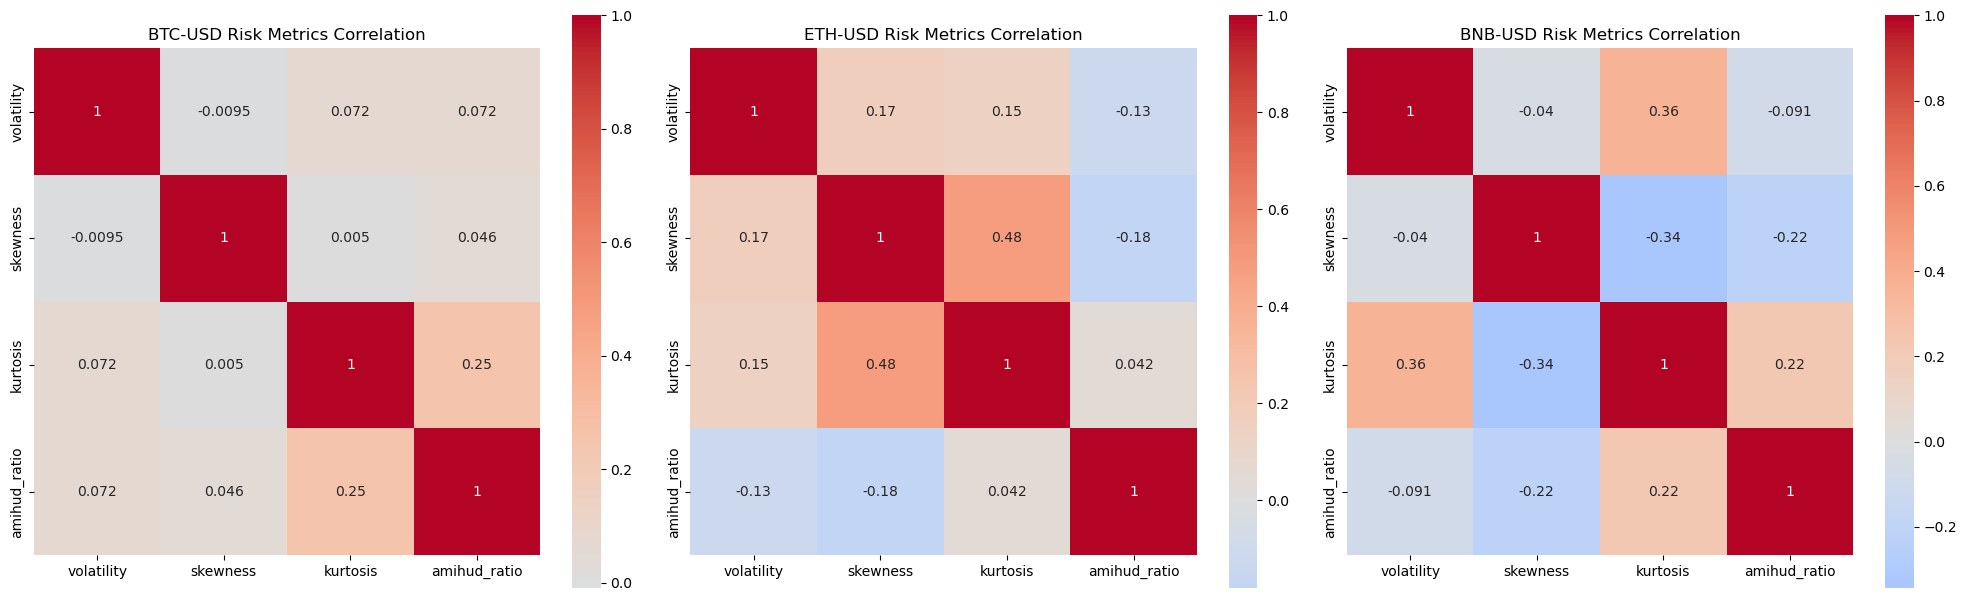

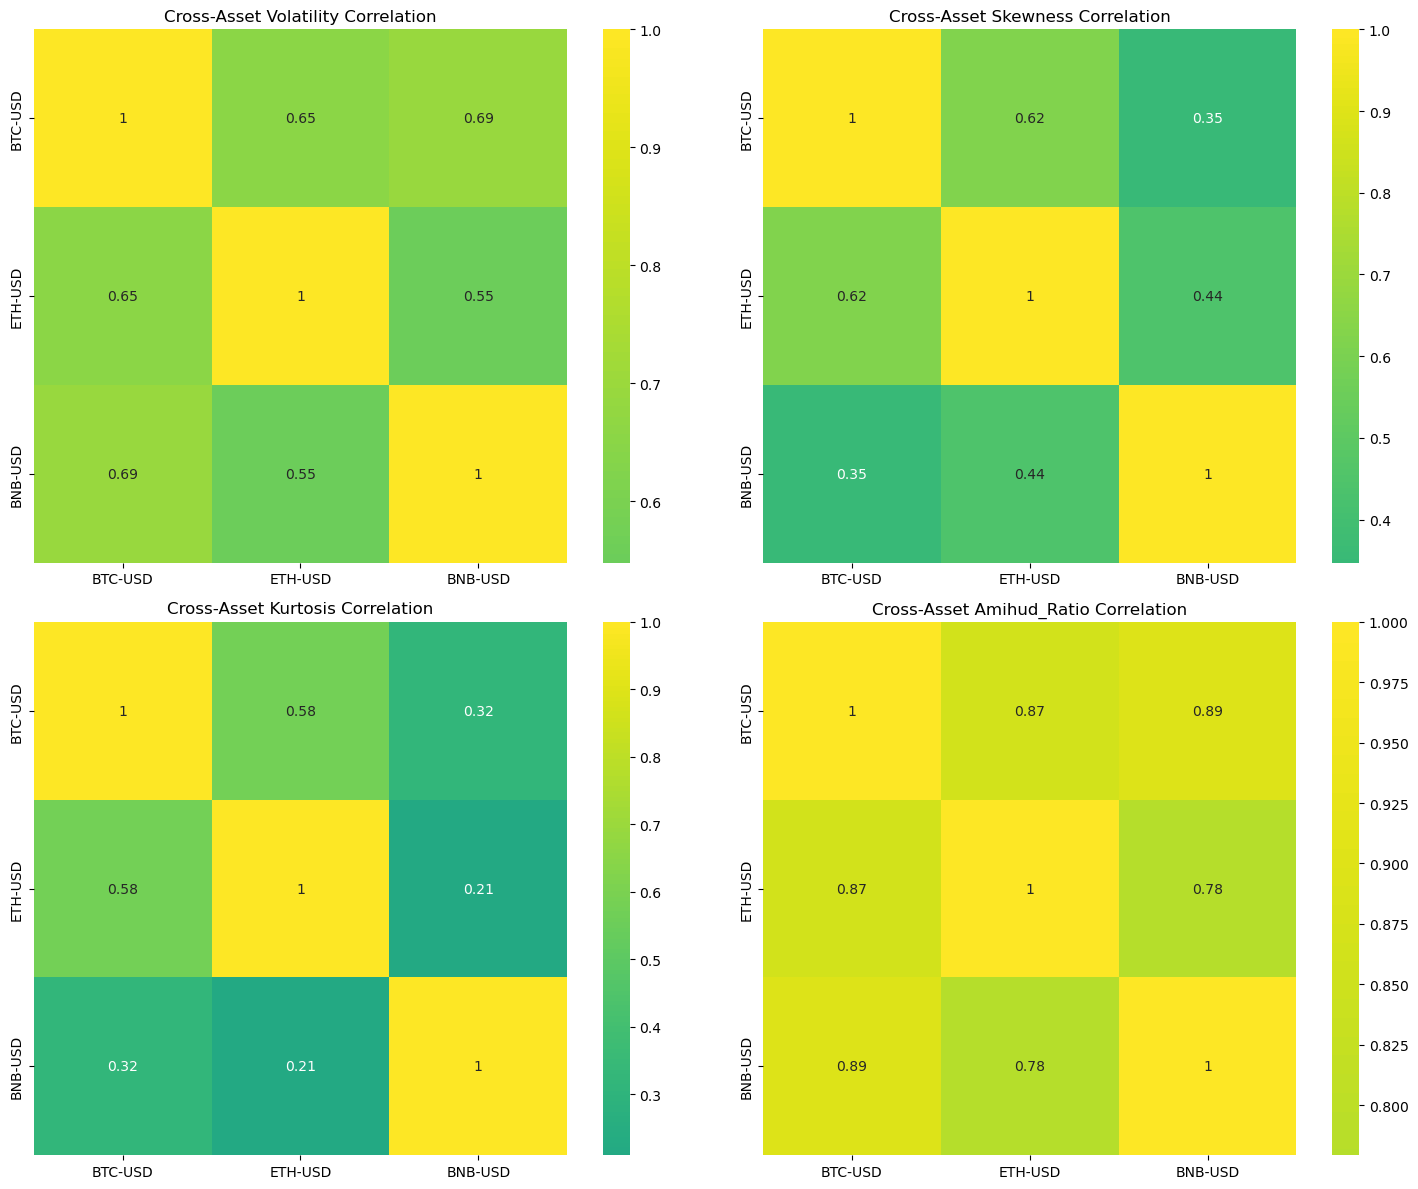

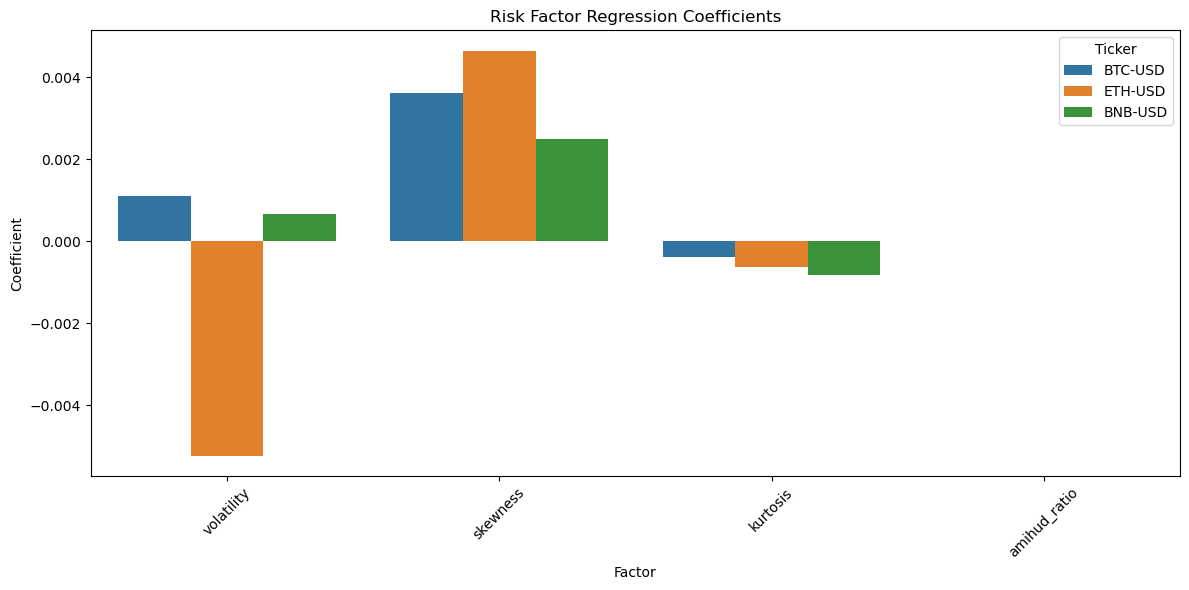

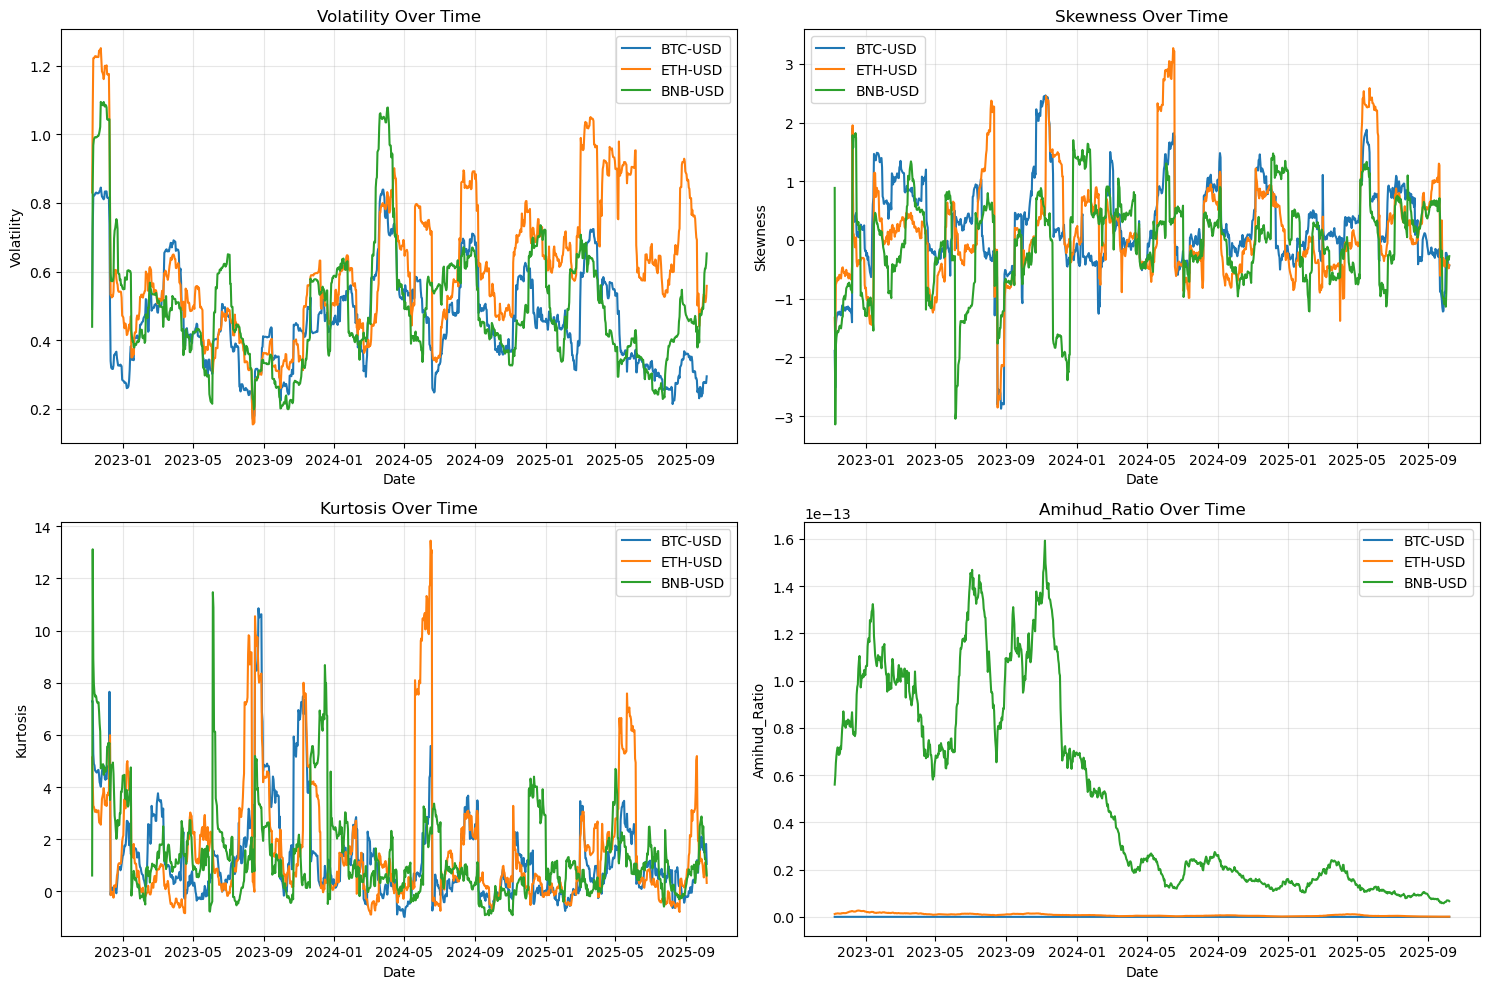

In [3]:
# Main analysis workflow
if __name__ == "__main__":
    
    # Calculate risk metrics
    risk_metrics, daily_returns = compute_required_risk_metrics(close_prices, volumes)
    
    # Regression analysis
    regression_results = risk_factor_regression_analysis(daily_returns, risk_metrics)
    
    # Display regression results
    display_regression_results(regression_results)
    
    # Create visualizations
    create_visualizations(risk_metrics, regression_results)
    
    # Save plots
    save_plots(risk_metrics, regression_results)